# Ridge L2 Regularization

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df=pd.read_csv("C:\\Users\\yuvra\\Downloads\\Ridge_Regression_HousingData.csv")

In [44]:
df.head()

,Unnamed: 0,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Median House Value
0,0,3.9816,27.0,4.928668,1.122476,3009.0,4.049798,33.73,-117.93,1.795
1,1,3.4531,23.0,4.021339,1.099338,2511.0,1.847682,34.14,-118.13,2.109
2,2,6.3942,4.0,5.681272,1.095774,5613.0,2.176425,37.78,-121.95,3.567
3,3,2.2243,32.0,5.685221,1.009597,1542.0,2.959693,38.69,-121.45,0.892
4,4,3.0217,9.0,5.006324,1.071146,3265.0,2.581028,37.69,-121.04,1.609


In [45]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          16512 non-null  int64  
 1   MedInc              16512 non-null  float64
 2   HouseAge            16512 non-null  float64
 3   AveRooms            16512 non-null  float64
 4   AveBedrms           16512 non-null  float64
 5   Population          16512 non-null  float64
 6   AveOccup            16512 non-null  float64
 7   Latitude            16512 non-null  float64
 8   Longitude           16512 non-null  float64
 9   Median House Value  16512 non-null  float64
dtypes: float64(9), int64(1)
memory usage: 1.3 MB


In [46]:
df.describe()

,Unnamed: 0,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Median House Value
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,8255.500000,3.859050,28.592902,5.429562,1.096896,1429.927689,3.055425,35.632512,-119.565484,2.062298
std,4766.748158,1.887126,12.615380,2.552593,0.494423,1149.664255,10.780690,2.133356,1.998334,1.151592
min,0.000000,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,4127.750000,2.562500,18.000000,4.439906,1.006131,785.000000,2.430205,33.930000,-121.790000,1.189000
50%,8255.500000,3.531300,29.000000,5.227757,1.048689,1168.000000,2.814815,34.260000,-118.500000,1.786000
75%,12383.250000,4.725000,37.000000,6.051724,1.099955,1729.000000,3.278159,37.710000,-118.007500,2.646000
max,16511.000000,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.490000,5.000010


<Axes: >

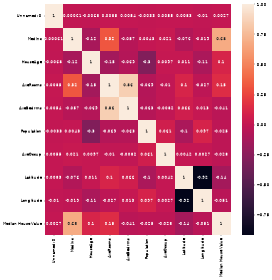

In [55]:
# make the heatmap
plt.figure(figsize=(10,10), dpi = 30)
sns.heatmap(df.corr(),annot = True)

In [48]:
x = df.drop(columns=["Median House Value", "Unnamed: 0"])
y = df["Median House Value"]

In [49]:
x = df.drop(columns=["Median House Value"])
y = df["Median House Value"]

In [50]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2, random_state = 23)

In [51]:
# Model training
from sklearn.linear_model import LinearRegression

# Model instance
LR = LinearRegression()

# train the model
model = LR.fit(x_train,y_train)

# predict the X_test
y_pred = model.predict(x_test)

In [52]:
# Model metrics
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score

# find metrics
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
r2_score = r2_score(y_test, y_pred)

#print the metrics
print("Mean Squared Error:", MSE)
print("Mean Absolute Error:", MAE)
print("R2 Score:", r2_score)

Mean Squared Error: 0.5393691658880787
Mean Absolute Error: 0.5285688709869792
R2 Score: 0.586180046315182


In [53]:
# model 2 : Ridge Regression
from sklearn.linear_model import Ridge

# create the instance
model = Ridge(alpha=1)

# train the model
model.fit(x_train,y_train)

# predict the X_test
y_pred_ridge = model.predict(x_test)
